# 01 · 数据理解与质量检查

本 Notebook 使用 `bank-additional-full.csv` 作为主分析集，完成字段概览、数据质量检查、目标变量分布和初步风险识别。

## 本阶段要回答的问题

- 数据共有多少客户记录和字段？
- 是否存在缺失值、重复记录或异常类别？
- 定期存款订购率是多少，是否存在类别不平衡？
- 哪些字段不能用于通话前的客户筛选？

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib import font_manager
import pandas as pd
import seaborn as sns

RANDOM_SEED = 42
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'data').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / 'data/raw/bank-additional/bank-additional/bank-additional-full.csv'
FIGURE_DIR = PROJECT_ROOT / 'figures/exploratory'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

for font_path in [Path('C:/Windows/Fonts/msyh.ttc'), Path('C:/Windows/Fonts/simhei.ttf')]:
    if font_path.exists():
        font_manager.fontManager.addfont(font_path)
        plt.rcParams['font.sans-serif'] = [font_manager.FontProperties(fname=font_path).get_name()]
        break
plt.rcParams['axes.unicode_minus'] = False

sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.max_columns', None)

In [2]:
assert DATA_PATH.exists(), f'未找到数据文件：{DATA_PATH.resolve()}'
df = pd.read_csv(DATA_PATH, sep=';')
print(f'数据集大小：{df.shape[0]:,} 行 × {df.shape[1]} 列')
df.head()

数据集大小：41,188 行 × 21 列


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 字段与数据质量概览

In [3]:
quality = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'missing_count': df.isna().sum(),
    'missing_rate': df.isna().mean(),
    'unique_values': df.nunique(),
}).sort_values(['missing_count', 'unique_values'], ascending=[False, False])

display(quality)
print(f'完全重复的记录数：{df.duplicated().sum():,}')
print(f"包含 'unknown' 的字段：{[col for col in df.select_dtypes(include=['object', 'string']) if (df[col] == 'unknown').any()]}")

,dtype,missing_count,missing_rate,unique_values
duration,int64,0,0.0,1544
euribor3m,float64,0,0.0,316
age,int64,0,0.0,78
campaign,int64,0,0.0,42
pdays,int64,0,0.0,27
cons.price.idx,float64,0,0.0,26
cons.conf.idx,float64,0,0.0,26
job,str,0,0.0,12
nr.employed,float64,0,0.0,11
month,str,0,0.0,10


完全重复的记录数：12
包含 'unknown' 的字段：['job', 'marital', 'education', 'default', 'housing', 'loan']


In [4]:
display(df.describe(include='all').T)
numeric_columns = df.select_dtypes(include='number').columns.tolist()
categorical_columns = df.select_dtypes(include=['object', 'string']).columns.tolist()
print('数值字段：', numeric_columns)
print('类别字段：', categorical_columns)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,41188.0,NaN,NaN,NaN,40.02406,10.42125,17.0,32.0,38.0,47.0,98.0
job,41188,12,admin.,10422,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,41188,4,married,24928,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,41188,8,university.degree,12168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,41188,3,no,32588,NaN,NaN,NaN,NaN,NaN,NaN,NaN
housing,41188,3,yes,21576,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,41188,3,no,33950,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,41188,2,cellular,26144,NaN,NaN,NaN,NaN,NaN,NaN,NaN
month,41188,10,may,13769,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day_of_week,41188,5,thu,8623,NaN,NaN,NaN,NaN,NaN,NaN,NaN


数值字段： ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
类别字段： ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'y']


## 目标变量：是否订购定期存款

,subscription,count,rate
0,no,36548,0.887346
1,yes,4640,0.112654


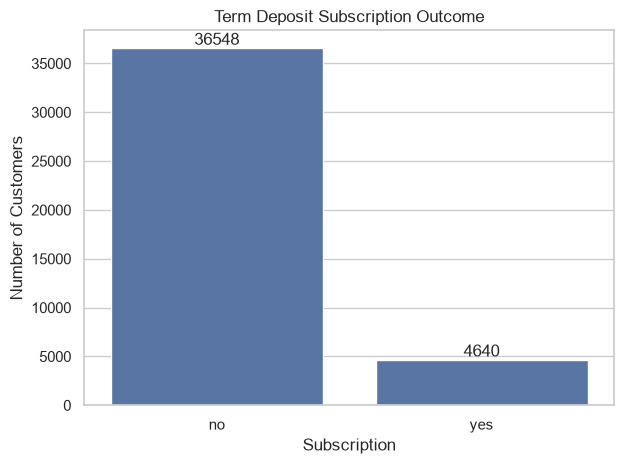

In [5]:
target_summary = (
    df['y'].value_counts(dropna=False)
    .rename_axis('subscription')
    .reset_index(name='count')
)
target_summary['rate'] = target_summary['count'] / len(df)
display(target_summary)

ax = sns.barplot(data=target_summary, x='subscription', y='count')
ax.set(title='Term Deposit Subscription Outcome', xlabel='Subscription', ylabel='Number of Customers')
for container in ax.containers:
    ax.bar_label(container, fmt='%d')
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'target_distribution.png', dpi=160, bbox_inches='tight')
plt.show()

## 建模前的重要风险

`duration` 是本次通话持续时间，只能在通话结束后得到。若目标是**通话前筛选客户**，它属于信息泄露，训练该场景的模型时必须排除；若目标是评估已完成通话的结果，可单独建立包含它的事后分析模型。

In [6]:
leakage_columns = ['duration']
modeling_candidates = df.columns.drop(['y', *leakage_columns]).tolist()
print('通话前预测可用字段数：', len(modeling_candidates))
print('需排除的信息泄露字段：', leakage_columns)

通话前预测可用字段数： 19
需排除的信息泄露字段： ['duration']


## 下一步

在 `02_data_cleaning.ipynb` 中确定 `unknown` 类别、重复记录和数据类型的处理策略，并将可复用的清洗逻辑转移到 `src/data.py`。